# PUF lifecycle and PUF-key AES

Set **LIVE=True** in the run cell for **new hardware results and new Python timings** every time you execute it. LIVE=False is explicitly labelled recorded hardware plus fresh Python; it never claims a new board measurement. Configure config.json first (see 10_hardware). No terminal programming step is needed.

The shared repository IPI image embeds bench.elf in BRAM. Each live run programs demo.pdi, streams UART timing rows, validates the complete suite, and reloads the configured recovery PDI. One full suite is run per notebook invocation; this notebook displays its relevant subset. No eFUSE or flash writes. Close other UART/debug clients before running.

Hardware timing uses the AXI Timer at nominal 100 MHz. Python uses perf_counter. Programming/UART/JTAG and recovery are outside device operation timing. Temporary live tables are provisional until final validation succeeds.

Registration, volatile key clear, same-helper regeneration and AES round trips are measured. A physical PUF has no Python equivalent, so its lifecycle timings are hardware-only; the fresh Python suite provides ordinary AES reference timings separately. Helper data and keys stay inside the device.

**Saved execution:** 2026-10-26T03:33:18.616519+00:00 (UTC). **fresh hardware + fresh Python**. Hardware cells were executed with `LIVE=True`. Portable defaults below are restored to `LIVE=False`; saved outputs are retained. To repeat on your board, configure it and enable the live flag. Boot outputs show acceptance/recovery and host verification times, not on-chip boot latency.

In [1]:
from pathlib import Path
import sys, os, json, time, hashlib
import pandas as pd
ROOT = next((p for base in [Path.cwd(), *Path.cwd().parents]
             for p in (base, base/'scu35') if (p/'lab.py').is_file()), None)
assert ROOT is not None, 'Open the notebook from the repository checkout'
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT/'host'))
from lab import config, tool
from notebook import runtime, show_runtime, LiveRows, command, hardware, check_build
c = config()
OUT = Path(c['build_dir']).resolve()
print('Python:', sys.executable)
print('Build:', OUT)


Python: C:\aiup\pubvenv\Scripts\python.exe
Build: C:\aiup\s35p2


,algorithm,case,bytes,SCU35 us (provisional),status
0,SHA3-256,valid,16,23.7215,0
1,SHA3-256,valid,64,23.7265,0
2,SHA3-256,valid,256,23.9355,0
3,SHA3-256,valid,1024,25.5155,0
4,SHA3-256,valid,2048,27.6215,0
5,SHAKE-256,valid,16,23.7445,0
6,SHAKE-256,valid,64,23.7470,0
7,SHAKE-256,valid,256,23.9545,0
8,SHAKE-256,valid,1024,25.5335,0
9,SHAKE-256,valid,2048,27.6395,0


FRESH HARDWARE run 1 of 1


RUN: hardware --mode runtime --pdi C:\aiup\s35p2\demo.pdi


 


TMR_TEST,carry,1,4117


...

HARDWARE_SESSION_PASS C:\aiup\s35p2\runs\20261025T213320


Fresh hardware and recovery PASS: C:\aiup\s35p2\runs\20261025T213320


Host session wall time (program/capture/recovery, NOT crypto latency): 45.73092510004062 s
Measuring fresh Python references…


C:\aiup\s35p2\runs\20261025T213320\comparison.html


,run,feature,repeats,cycles,mean_us,status
0,1,PUF-REGISTER,1,33715,337.15,0
1,1,PUF-AES-ENC,1,4070,40.70,0
2,1,PUF-KEY-CLEAR,5,1470,2.94,0
3,1,PUF-REGENERATE,5,284105,568.21,0
4,1,PUF-AES-DEC,5,17360,34.72,0


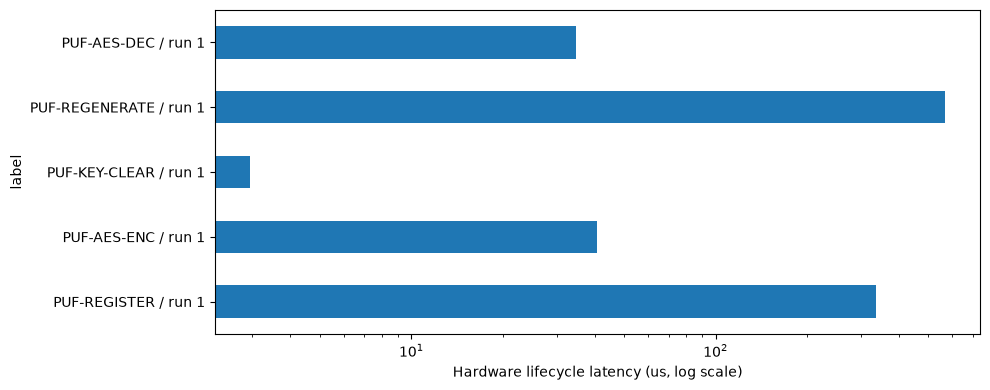

PUF has no physical Python equivalent. No synthetic PUF timing is reported.
FRESH HARDWARE + FRESH PYTHON: C:\aiup\s35p2\runs\20261025T213320\comparison.html
Device processing rates exclude programming/UART/JTAG. They are not physical bus bandwidth measurements.


In [2]:
LIVE = False  # Set True to program the configured SCU35 and measure it now
REPEATS = 1   # Increase for independent program/capture/Python benchmark runs
PYTHON_SAMPLES = 1000
PQ_SAMPLES = 50
progress = LiveRows(algorithms=None) if LIVE else None
reports = runtime(live=LIVE, repeats=REPEATS, samples=PYTHON_SAMPLES,
                  pq_samples=PQ_SAMPLES, on_line=progress, c=c)
comparison = show_runtime(reports, algorithms=None, feature_prefix='PUF')


## Repeat and audit
Rerun the cell above for new timings. Increase REPEATS for a series of independent captures. Each live session has its own UART log, session.json, program/restore logs, comparison.html and notebook_report.json in <build_dir>/runs/. Compare timestamps and hashes to distinguish runs. A live failure raises an error and preserves logs; it never substitutes saved results.

SCU35 operation latency includes setup for hashes/AES and the API interval for signatures. Full copy/setup/check timing is retained in the report. Python uses optimized native hash/AES libraries and Python signature control flow. Negative signature rates represent rejection work, not successful verifications/s.

In [3]:
display(pd.DataFrame(reports[-1]['comparisons']).query("algorithm in ['AES-GCM-ENC', 'AES-GCM-DEC']")[[
    'algorithm', 'size_bytes', 'python_mean_us']])
print('Ordinary public-keyed AES software baseline; NOT software PUF emulation.')

,algorithm,size_bytes,python_mean_us
10,AES-GCM-ENC,16,1.4746
11,AES-GCM-ENC,64,1.4973
12,AES-GCM-ENC,256,1.7695
13,AES-GCM-ENC,1024,1.9115
14,AES-GCM-ENC,2048,2.2597
15,AES-GCM-DEC,16,1.2882
16,AES-GCM-DEC,64,1.2921
17,AES-GCM-DEC,256,1.3409
18,AES-GCM-DEC,1024,1.6114
19,AES-GCM-DEC,2048,2.8550


Ordinary public-keyed AES software baseline; NOT software PUF emulation.
